<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Procesamiento de Lenguaje Natural · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Preprocesamiento y Representación TF-IDF del Conjunto de Datos POLAR (SemEval-2026 Task 9)</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Pérez Martínez Ángel Noel, Zamora Antiga Ángel Javier</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Objetivo</span></div>

Limpiar los textos de los 22 idiomas con un mismo procedimiento y construir su representación vectorial con TF-IDF sobre n-gramas de caracteres, que servirá como entrada a los clasificadores de la siguiente etapa.

Se descartó la lematización porque las herramientas disponibles (NLTK, spaCy, Stanza) no cubren todos los idiomas del conjunto, y se tendría un preprocesamiento distinto para cada uno. Los n-gramas de caracteres resuelven buena parte del mismo problema sin depender del idioma: palabras con la misma raíz comparten la mayoría de sus n-gramas, no es necesario separar palabras en chino, jemer o birmano, y son tolerantes a faltas de ortografía.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Preparación de entorno</span></div>

In [1]:
# Manejo de datos
import os
import re
import glob
import unicodedata
import joblib
import numpy as np
import pandas as pd
from scipy import sparse

# Procesamiento de texto
import regex
import emoji
from sklearn.feature_extraction.text import TfidfVectorizer

# Visualización
import matplotlib.pyplot as plt

# Reproducibilidad
random_state = 42

# Rutas y grupos de etiquetas por subtarea
ruta_datos = 'data'
ruta_procesado = os.path.join(ruta_datos, 'procesado')
ruta_tfidf = os.path.join(ruta_datos, 'tfidf')
tipos = ['political', 'racial/ethnic', 'religious', 'gender/sexual', 'other']
manifestaciones = ['stereotype', 'vilification', 'dehumanization', 'extreme_language', 'lack_of_empathy', 'invalidation']
etiquetas = ['polarization'] + tipos + manifestaciones

pd.set_option('display.max_colwidth', 200)

Para las expresiones regulares se usa el módulo `regex` en lugar de `re`. En `re`, la clase `\w` no incluye las marcas combinantes (categorías Unicode `Mn` y `Mc`), que en escrituras como el devanagari, el telugu, el jemer o el birmano representan las vocales. Al eliminar "todo lo que no sea `\w`", `re` destruye las palabras; `regex` permite usar las categorías Unicode de forma explícita (`\p{L}` letras, `\p{M}` marcas, `\p{N}` números).

In [2]:
# re vs regex con escrituras que usan marcas combinantes
ejemplo = 'हिन्दी తెలుగు ខ្មែរ မြန်မာ'
print(f"Original: {ejemplo}")
print(f"re:       {re.sub(r'[^\w\s]', '', ejemplo)}")
print(f"regex:    {regex.sub(r'[^\p{L}\p{M}\p{N}\s]', '', ejemplo)}")

Original: हिन्दी తెలుగు ខ្មែរ မြန်မာ
re:       हनद తలగ ខមរ မနမ
regex:    हिन्दी తెలుగు ខ្មែរ မြန်မာ


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Carga de datos</span></div>

In [3]:
def cargar_particion(particion):
    """
    Función que carga y concatena los archivos de todos los idiomas de una partición

    inputs:
    --------
        particion (str): Nombre de la carpeta ('train' o 'test')

    outputs:
    --------
        pandas.DataFrame: Registros de todos los idiomas con una columna adicional 'idioma'
    """
    archivos = sorted(glob.glob(os.path.join(ruta_datos, particion, '*.csv')))
    dfs = [pd.read_csv(f).assign(idioma = os.path.basename(f)[:3]) for f in archivos]
    return pd.concat(dfs, ignore_index = True)

train = cargar_particion('train')
test = cargar_particion('test').drop(columns = ['canary'])
idiomas = sorted(train['idioma'].unique())

print(f'Tamaño de train: {train.shape}')
print(f'Tamaño de test: {test.shape}')

Tamaño de train: (73681, 15)
Tamaño de test: (33288, 15)


En el análisis exploratorio se encontraron textos de prueba que también aparecen en entrenamiento. Se eliminan de `train` para que la evaluación no esté contaminada.

In [4]:
# Textos de train que también están en test
fuga = train['text'].isin(test['text'])
display(train.loc[fuga, ['id', 'idioma', 'text', 'polarization']]
        .merge(test[['id', 'text', 'polarization']], on = 'text', suffixes = ('_train', '_test')))

train = train[~fuga].reset_index(drop = True)
print(f'Registros eliminados de train: {fuga.sum()}')

,id_train,idioma,text,polarization_train,id_test,polarization_test
0,pan_7b397b165ec40faf3f6c7c32a9e6ae05,pan,دوست مزاری پر اصولاً یہاں توہین عدالت اور آئین کی خلاف ورزی کی شقیں بھی لگ سکتی. لیکن ایتھے کیہڑے اصول,0,urd_7b397b165ec40faf3f6c7c32a9e6ae05,1
1,tur_63390f8d0fbf81e2f2a406d41fa6f1ef,tur,"@USER @USER Esasında sizin burada Ak Partiyi itham ve iftiralarınıza suç duyurusu şart ,5 dakikalığına kiraya verdiğiniz aklınızı geri alabilseniz tüm çıplaklığıyla gerçekleri hakikatları göreceks...",1,tur_63390f8d0fbf81e2f2a406d41fa6f1ef,1
2,tur_7f30cd79b49984d0648dd4e717bba7bf,tur,@USER Avukatlığını yaptığın Rusya orada ABD hesabına çalışıyor. Sivil halka yöneklik pis işi kontrat üzerine yapıyor. Gerçi o kadar İslamcı teröristi oraya sokan da ABD ve onun mafya tetikçisi Rus...,1,tur_7f30cd79b49984d0648dd4e717bba7bf,1
3,tur_9d62f60bd9122f26bfa5204f50cfb037,tur,@USER @USER Yorumlara bakinca Amerikalıların ne kadar cahil bir toplum olduğu çok net görünüyor.,0,tur_9d62f60bd9122f26bfa5204f50cfb037,1


Registros eliminados de train: 4


Se eliminaron 4 registros de `train`. Los tres de turco tienen el mismo `id` en ambas particiones, así que es el mismo registro repetido. El cuarto es un texto en panyabí escrito en alfabeto shahmukhi (derivado del árabe, como el urdu), que aparece como `pan` en `train` y como `urd` en `test` con el mismo hash en el `id`. En dos de los cuatro casos la etiqueta de polarización no coincide entre particiones, lo que muestra que la anotación tiene algo de ruido.

In [5]:
# Se unen ambas particiones para aplicar cada paso de limpieza una sola vez
datos = pd.concat([train.assign(particion = 'train'), test.assign(particion = 'test')], ignore_index = True)
datos['texto'] = datos['text']
print(f'Registros totales: {len(datos)}')

Registros totales: 106965


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Limpieza de texto</span></div>

La limpieza se aplica en el siguiente orden, porque algunos pasos dependen de los anteriores:

1. Normalización Unicode
2. Unificación de marcadores (`@USER`, `@URL` y sus variantes)
3. Reducción de caracteres repetidos
4. Conversión de emojis a texto
5. Eliminación del símbolo `#` de los hashtags
6. Puntuación: los signos de fin de oración se convierten en punto y todo lo demás se elimina
7. Conversión a minúsculas
8. Espacios

Como después de cada paso se revisa qué textos cambió, esa revisión se define como función.

In [6]:
def mostrar_cambios(antes, despues, n = 4, largo_max = 160):
    """
    Función que reporta cuántos textos modificó un paso de limpieza y muestra algunos ejemplos

    inputs:
    --------
        antes (pandas.Series): Textos antes de aplicar el paso
        despues (pandas.Series): Textos después de aplicar el paso
        n (int): Cantidad de ejemplos a mostrar
        largo_max (int): Longitud máxima de los ejemplos, para que el cambio sea visible

    outputs:
    --------
        None
    """
    cambio = antes != despues
    print(f'Textos modificados: {cambio.sum()} ({round(100 * cambio.mean(), 2)}%)')
    candidatos = cambio & (antes.str.len() <= largo_max)
    if candidatos.sum() >= n:
        muestra = antes[candidatos].sample(n, random_state = random_state).index
        display(pd.DataFrame({'idioma': datos.loc[muestra, 'idioma'],
                              'antes': antes[muestra],
                              'después': despues[muestra]}))

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Normalización Unicode</span></div>

Un mismo carácter puede codificarse de varias formas: con un solo código o como letra base más marca combinante, en versión de ancho completo (común en chino) o como forma de presentación (común en árabe). La normalización **NFKC** lleva todas estas variantes a una sola forma canónica; por ejemplo, `ＡＢＣ` → `ABC`, `？` → `?` y `…` → `...`. Esto también simplifica el paso de puntuación.

In [7]:
antes = datos['texto'].copy()
datos['texto'] = datos['texto'].map(lambda t: unicodedata.normalize('NFKC', t))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 11491 (10.74%)


,idioma,antes,después
73181,zho,对对对，台湾人对我们的恨意是远大于外国人的，外国人哪怕是歧视也只是讨厌的程度，台湾人是真的仇视,"对对对,台湾人对我们的恨意是远大于外国人的,外国人哪怕是歧视也只是讨厌的程度,台湾人是真的仇视"
90089,mya,မ ဆိုး ပါ ဘူး ဘာ ပဲ ပြောပြော အနုပညာ သဘော ပဲ ကြည့် ကြ ပါ ဗျာ တဏှာ ဘက် က မ ကြည့် ကြ နဲ့ ပေါ့,မ ဆိုး ပါ ဘူး ဘာ ပဲ ပြောပြော အနုပညာ သဘော ပဲ ကြည့် ကြ ပါ ဗျာ တဏှာ ဘက် က မ ကြည့် ကြ နဲ့ ပေါ့
6920,ben,সময় টিভির অসময় অচিরে আসবে ছোট্ট খাটো গুলো খেয়ে লাভ নেই বেচে বেচে অবৈধ সরকারের ডিজিটাল কুত্তা লীগ পুলিশ খেলে দেশের জনগণ একটু শান্তি তে থাকতে পারবে,সময় টিভির অসময় অচিরে আসবে ছোট্ট খাটো গুলো খেয়ে লাভ নেই বেচে বেচে অবৈধ সরকারের ডিজিটাল কুত্তা লীগ পুলিশ খেলে দেশের জনগণ একটু শান্তি তে থাকতে পারবে
72294,zho,那个 山东也是全国 排名靠前的省，不过全国哪里都有经济条件没那么好的人吧,"那个 山东也是全国 排名靠前的省,不过全国哪里都有经济条件没那么好的人吧"


Se modificó cerca del 11% de los textos. En la mayoría el cambio no se ve a simple vista porque solo cambia la codificación interna (por ejemplo, en bengalí y birmano, letras compuestas que se representaban con dos códigos). En chino sí se nota: las comas de ancho completo `，` pasan a `,`, y así el paso de puntuación las reconoce como cualquier otra coma.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Marcadores de usuario y enlaces</span></div>

El conjunto ya anonimiza menciones y enlaces, pero no de la misma forma en todos los idiomas. Se unifican en dos tokens, `xxuser` y `xxurl`, que no existen en ningún idioma y que no se confunden con las palabras *user* o *url* al pasar a minúsculas. `<nl>` marca saltos de línea, así que se sustituye por un espacio.

In [8]:
# Variantes de marcadores presentes en el corpus
patron_marcadores = r'@USER\b|\[pseudonym\]|@URL\b|##url\b|\[URL\]|https?://\S+|<nl>'
variantes = datos['texto'].str.findall(patron_marcadores).explode().dropna()
print(variantes.str.replace(r'https?://\S+', 'http(s)://...', regex = True).value_counts())

texto
@USER          13792
@URL            2318
##url           1551
[URL]            184
[pseudonym]       49
<nl>              28
Name: count, dtype: int64


In [9]:
antes = datos['texto'].copy()
datos['texto'] = (datos['texto']
                  .str.replace(r'@USER\b|\[pseudonym\]', ' xxuser ', regex = True)
                  .str.replace(r'@URL\b|##url\b|\[URL\]|https?://\S+', ' xxurl ', regex = True)
                  .str.replace('<nl>', ' ', regex = False))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 13587 (12.7%)


,idioma,antes,después
26385,ita,"Qui Radio Londra: Tre arresti nel nord Italia, reclutavano terroristi jihadisti - l'@URL @URL","Qui Radio Londra: Tre arresti nel nord Italia, reclutavano terroristi jihadisti - l' xxurl xxurl"
28000,ita,@USER Ipocriti farabutti. Fanno morire i terremotati per I Bastardi clandestini immigrati schifosi.,xxuser Ipocriti farabutti. Fanno morire i terremotati per I Bastardi clandestini immigrati schifosi.
104890,urd,گستاخ صحابہ کا لیگلی ذلیل ہونے کا ٹائم ہوا چاہتا @URL #گستاخان_صحابہ_آؤعدالت,گستاخ صحابہ کا لیگلی ذلیل ہونے کا ٹائم ہوا چاہتا xxurl #گستاخان_صحابہ_آؤعدالت
20512,hau,@USER kaji ‘yan wuta munafikai,xxuser kaji ‘yan wuta munafikai


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Caracteres repetidos</span></div>

Las secuencias de tres o más caracteres iguales se reducen a dos (`nooooo` → `noo`). Se conservan dos y no uno para no perder del todo el énfasis y para no alterar palabras que llevan letras dobles legítimas. Los dígitos se excluyen para no modificar cifras como `1000`.

Este paso va antes de convertir los emojis, de modo que `😂😂😂😂` se reduce a `😂😂` mientras sigue siendo un solo carácter repetido.

In [10]:
antes = datos['texto'].copy()
datos['texto'] = datos['texto'].map(lambda t: regex.sub(r'([^\d\s])\1{2,}', r'\1\1', t))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 9733 (9.1%)


,idioma,antes,después
6005,arb,بالنسبة الخليجيين اهم من كأس العالم...... أصلا الخليجيين لا يتأهلون للمونديال,بالنسبة الخليجيين اهم من كأس العالم.. أصلا الخليجيين لا يتأهلون للمونديال
100991,swa,Wajaluo maumbwa kabla utaje jina kubwa UHURU ama RUTO ufkirie mara mbili hawa ni wanaume na nusu wanaume wenye...,Wajaluo maumbwa kabla utaje jina kubwa UHURU ama RUTO ufkirie mara mbili hawa ni wanaume na nusu wanaume wenye..
54640,swa,wahindi wanatafuta nini hawa kubabeki...,wahindi wanatafuta nini hawa kubabeki..
69597,zho,哈哈哈南非不是发达过家恐怕也只有你跪虫族会说它曾经不是,哈哈南非不是发达过家恐怕也只有你跪虫族会说它曾经不是


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Emojis</span></div>

Los emojis pueden indicar burla u hostilidad, así que se conservan como texto con `emoji.demojize`. Cada emoji se convierte en su nombre en inglés, unido con guiones bajos y separado por espacios, para que quede como un token independiente: `😂` → ` face_with_tears_of_joy `.

In [11]:
# Emojis más frecuentes
lista_emojis = datos['texto'].map(lambda t: [e['emoji'] for e in emoji.emoji_list(t)]).explode().dropna()
print(f"Textos con al menos un emoji: {datos['texto'].map(emoji.emoji_count).gt(0).sum()}")
frecuentes = lista_emojis.value_counts().head(10)
display(pd.DataFrame({'emoji': frecuentes.index,
                      'nombre': [emoji.demojize(e, delimiters = ('', '')) for e in frecuentes.index],
                      'frecuencia': frecuentes.values}))

Textos con al menos un emoji: 6453


,emoji,nombre,frecuencia
0,😂,face_with_tears_of_joy,2404
1,🤣,rolling_on_the_floor_laughing,948
2,🙏,folded_hands,413
3,😁,beaming_face_with_smiling_eyes,377
4,😅,grinning_face_with_sweat,267
5,😭,loudly_crying_face,262
6,🤔,thinking_face,228
7,😡,enraged_face,223
8,🚩,triangular_flag,187
9,😎,smiling_face_with_sunglasses,175


In [12]:
antes = datos['texto'].copy()
datos['texto'] = datos['texto'].map(lambda t: emoji.demojize(t, delimiters = (' ', ' ')))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 6472 (6.05%)


,idioma,antes,después
94320,pol,"Po pracy, odsłuchamy wspólnie to nagranie 😎","Po pracy, odsłuchamy wspólnie to nagranie smiling_face_with_sunglasses"
37733,mya,ဘုရား ဆို တာ နဲ့ ရှင် ဂေါတမ ကို ပဲ ဘုရား လို့ ထင် နေ ကြ တဲ့ ဗုဓ်ပေါ တွေ က လည်း ဒု နဲ့ ဒေး 🥴🥴,ဘုရား ဆို တာ နဲ့ ရှင် ဂေါတမ ကို ပဲ ဘုရား လို့ ထင် နေ ကြ တဲ့ ဗုဓ်ပေါ တွေ က လည်း ဒု နဲ့ ဒေး woozy_face woozy_face
68684,urd,قوم لوط پر عذاب ہم جنس پرستی کی وجہ سے آیا تھا اور یہ لوگ بھول گئے فلم جوائے لینڈ رلیز کرنے لگے ہیں😢 #BanJoyLand_BehayaGovt,قوم لوط پر عذاب ہم جنس پرستی کی وجہ سے آیا تھا اور یہ لوگ بھول گئے فلم جوائے لینڈ رلیز کرنے لگے ہیں crying_face #BanJoyLand_BehayaGovt
13162,deu,nain halo okbrudimongoh daführ muhs man schraiben könen duh ludscha daß kahn ehr aba niecht 😡😤,nain halo okbrudimongoh daführ muhs man schraiben könen duh ludscha daß kahn ehr aba niecht enraged_face face_with_steam_from_nose


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Hashtags</span></div>

Se elimina el símbolo `#` y se conserva la palabra, porque en varios idiomas el hashtag contiene información relevante (`#immigrati`, `#italiani`, `#TPLF`).

In [13]:
# Idiomas con más hashtags
print(datos.loc[datos['texto'].str.contains(r'#\w', regex = True), 'idioma'].value_counts().head(8))

antes = datos['texto'].copy()
datos['texto'] = datos['texto'].str.replace(r'#(?=\w)', '', regex = True)
mostrar_cambios(antes, datos['texto'])

idioma
urd    1191
ita     851
hin     770
tur     741
amh     407
pol     311
hau     301
swa     287
Name: count, dtype: int64
Textos modificados: 7902 (7.39%)


,idioma,antes,después
103782,urd,بھکاری شریف وطن بدنصیب کے 23ویں کرائم منسٹر منتخب. #امپورٹڈ_حکومٹ_نامنظور,بھکاری شریف وطن بدنصیب کے 23ویں کرائم منسٹر منتخب. امپورٹڈ_حکومٹ_نامنظور
17800,fas,فوری: حجت الاسلام والمسلمین سجاد شهرکی امام جماعت مسجد مولای متقیان(ع) #زاهدان ترور شد. #مهسا_امینی,فوری: حجت الاسلام والمسلمین سجاد شهرکی امام جماعت مسجد مولای متقیان(ع) زاهدان ترور شد. مهسا_امینی
93295,pan,سندھیلہ صاحب تسی نا تشہیر کرو کسی بچے کولوں کروا لو #یوم_نجات,سندھیلہ صاحب تسی نا تشہیر کرو کسی بچے کولوں کروا لو یوم_نجات
51685,spa,#chvnoticias la muerte de ninos no se transa por el dinero judio,chvnoticias la muerte de ninos no se transa por el dinero judio


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Puntuación</span></div>

Solo se conservan los puntos como marca de fin de oración. Además del `.?!¿¡` del español, cada escritura tiene sus propios signos de fin de oración (la *danda* `।` del hindi y el bengalí, `።` del amhárico, `؟` y `۔` del árabe y el urdu, `။` del birmano, `។` del jemer, `。` del chino). Todos ellos se identifican con la propiedad Unicode `Sentence_Terminal`, así que se tratan igual que `?` y `!`.

El proceso es el siguiente:

1. Se quitan los separadores dentro de números (`3.5` → `35`, `1,000` → `1000`), para que no se confundan con un punto final.
2. Se quitan los apóstrofos para no partir palabras (`don't` → `dont`).
3. Se quitan los caracteres invisibles de formato (categoría Unicode `Cf`). El más común es el *zero width non-joiner*, que en persa y telugu va dentro de las palabras, así que se elimina sin dejar espacio.
4. Cualquier carácter que no sea letra, marca combinante, número, guion bajo (de los emojis), espacio o signo de fin de oración se sustituye por un espacio.
5. Cada secuencia de signos de fin de oración, aunque tenga espacios intermedios, se convierte en un solo punto (`???` → `.`, `!! ?` → `.`).

In [14]:
fin_oracion = r'[\p{Sentence_Terminal}¿¡]'
otros_signos = r'[^\p{L}\p{M}\p{N}_\s\p{Sentence_Terminal}¿¡\p{Cf}]'

# Caracteres invisibles de formato
print('\t Caracteres de formato:')
print(datos['texto'].map(lambda t: regex.findall(r'\p{Cf}', t)).explode().dropna()
      .map(lambda c: unicodedata.name(c, hex(ord(c)))).value_counts().head(6))

# Signos de fin de oración más frecuentes
print('\t Signos de fin de oración:')
print(datos['texto'].map(lambda t: regex.findall(fin_oracion, t)).explode().dropna().value_counts().head(12))

# Caracteres que se eliminarán
print('\n\t Caracteres sustituidos por espacio más frecuentes:')
print(datos['texto'].map(lambda t: regex.findall(otros_signos, t)).explode().dropna().value_counts().head(12))

	 Caracteres de formato:


texto
ZERO WIDTH NON-JOINER    3268
ZERO WIDTH JOINER          64
ZERO WIDTH SPACE           49
RIGHT-TO-LEFT MARK         30
WORD JOINER                10
LEFT-TO-RIGHT ISOLATE      10
Name: count, dtype: int64
	 Signos de fin de oración:


texto
.    54193
!    12441
?    11268
។     7657
।     7574
。     3021
۔     2948
።     2304
؟     1926
။     1253
၊      636
៕      368
Name: count, dtype: int64

	 Caracteres sustituidos por espacio más frecuentes:


texto
,    38536
:     7972
"     7690
-     7466
'     5420
،     4704
)     4683
(     3984
|     1630
’     1591
/     1486
*     1092
Name: count, dtype: int64


In [15]:
antes = datos['texto'].copy()

# Separadores dentro de números y apóstrofos
datos['texto'] = datos['texto'].map(lambda t: regex.sub(r'(?<=\d)[.,](?=\d)', '', t))
datos['texto'] = datos['texto'].str.replace(r"['’]", '', regex = True)

# Caracteres invisibles de formato, sin dejar espacio
datos['texto'] = datos['texto'].map(lambda t: regex.sub(r'\p{Cf}', '', t))

# Todo lo demás se sustituye por un espacio
datos['texto'] = datos['texto'].map(lambda t: regex.sub(otros_signos, ' ', t))

# Secuencias de signos de fin de oración a un solo punto
datos['texto'] = datos['texto'].map(lambda t: regex.sub(rf'[\s¿¡\p{{Sentence_Terminal}}]*{fin_oracion}[\s¿¡\p{{Sentence_Terminal}}]*', '. ', t))

mostrar_cambios(antes, datos['texto'])

Textos modificados: 67827 (63.41%)


,idioma,antes,después
3468,arb,رئيس هيئة حقوق الإنسان: السعودية حريصة على نصرة القضايا العادلة,رئيس هيئة حقوق الإنسان السعودية حريصة على نصرة القضايا العادلة
44009,pan,مومن مسلماناں تائیں کرن مزاخ بھلیرے، ڈُوماں بھنڈاں دا ایہہ صیغہ,مومن مسلماناں تائیں کرن مزاخ بھلیرے ڈُوماں بھنڈاں دا ایہہ صیغہ
91554,nep,मनोवैज्ञानिकरूपमा यस्ता प्रक्रियाले महिलालाई कमजोर बनाएको पाइन्छ जस्ले गर्दा महिलाको समग्र विकासमा नै असर परिराखेको हुन्छ।,मनोवैज्ञानिकरूपमा यस्ता प्रक्रियाले महिलालाई कमजोर बनाएको पाइन्छ जस्ले गर्दा महिलाको समग्र विकासमा नै असर परिराखेको हुन्छ.
15093,eng,"Milwaukee Palestinian, Israeli officials outraged over war",Milwaukee Palestinian Israeli officials outraged over war


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Minúsculas</span></div>

Se pasa todo a minúsculas para que `Odio`, `ODIO` y `odio` cuenten como la misma palabra. Solo afecta a las escrituras con mayúsculas (latina, cirílica). Se pierde la señal de las mayúsculas sostenidas, pero los signos de exclamación ya quedaron registrados como puntos.

El turco requiere un trato especial: su `I` mayúscula corresponde a la `ı` sin punto y su `İ` a la `i`, mientras que `str.lower()` aplica la regla de los demás idiomas.

In [16]:
antes = datos['texto'].copy()

es_turco = datos['idioma'] == 'tur'
datos.loc[es_turco, 'texto'] = datos.loc[es_turco, 'texto'].str.replace('I', 'ı').str.replace('İ', 'i')
datos['texto'] = datos['texto'].str.lower()

mostrar_cambios(antes, datos['texto'])

Textos modificados: 31550 (29.5%)


,idioma,antes,después
15996,eng,We want Recount of pp7,we want recount of pp7
13907,eng,The Deep State will Deep State.,the deep state will deep state.
80672,eng,Democrats denounce rightwing news pipeline used,democrats denounce rightwing news pipeline used
13801,eng,We now live under a fascist government.,we now live under a fascist government.


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Espacios</span></div>

Los pasos anteriores dejaron espacios múltiples y algunos puntos al inicio del texto (por ejemplo, de un `¿` inicial). Se colapsan los espacios y se eliminan los puntos iniciales.

In [17]:
antes = datos['texto'].copy()
datos['texto'] = (datos['texto']
                  .str.replace(r'\s+', ' ', regex = True)
                  .str.strip()
                  .str.replace(r'^\.\s*', '', regex = True))
mostrar_cambios(antes, datos['texto'])

Textos modificados: 68940 (64.45%)


,idioma,antes,después
33824,khm,ព្រោះប្អូនៗដែលស្ថិតក្នុងវ័យចាយលុយម៉ាក់ប៉ាគឺពួកគាត់អាចនឹងយល់ច្រលំការសិក្សានៅសាលា ខំរៀនតែនៅក្នុងសាលារៀន.,ព្រោះប្អូនៗដែលស្ថិតក្នុងវ័យចាយលុយម៉ាក់ប៉ាគឺពួកគាត់អាចនឹងយល់ច្រលំការសិក្សានៅសាលា ខំរៀនតែនៅក្នុងសាលារៀន.
61332,tel,ఆన్లైన్ ఫుడ్ డెలివరీ యాప్ల రాక రెస్టారెంట్ పరిశ్రమతో పాటు టాక్సీ మరియు క్యాబ్ పరిశ్రమ తరహాలోనే రవాణా వ్యవస్థపై ఆధారపడి పనిచేస్తుంది,ఆన్లైన్ ఫుడ్ డెలివరీ యాప్ల రాక రెస్టారెంట్ పరిశ్రమతో పాటు టాక్సీ మరియు క్యాబ్ పరిశ్రమ తరహాలోనే రవాణా వ్యవస్థపై ఆధారపడి పనిచేస్తుంది
61495,tel,మౌలిక సదుపాయాలు లేకపోతున్నాయి ఆస్పద.,మౌలిక సదుపాయాలు లేకపోతున్నాయి ఆస్పద.
5466,arb,١٦ ديسمبر ٢٠٢٤. حكام سوريا الجدد الارهابيين قرروا الغاء التجنيد الاجباري والخدمة العسكرية ليست فرضا على السوريين الان,١٦ ديسمبر ٢٠٢٤. حكام سوريا الجدد الارهابيين قرروا الغاء التجنيد الاجباري والخدمة العسكرية ليست فرضا على السوريين الان


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Resultado de la limpieza</span></div>

In [18]:
# Caracteres que no son letras, marcas ni números después de la limpieza
restantes = pd.Series(list(''.join(datos['texto']))).value_counts()
restantes = restantes[[not unicodedata.category(c).startswith(('L', 'M', 'N')) for c in restantes.index]]
print('\t Caracteres no alfanuméricos restantes:')
print(restantes.rename(index = {' ': 'espacio'}))
print(f"\n Textos vacíos tras la limpieza: {(datos['texto'].str.len() == 0).sum()}")

	 Caracteres no alfanuméricos restantes:
espacio    1608505
.            90585
_            33765
Name: count, dtype: int64

 Textos vacíos tras la limpieza: 0


In [19]:
# Un ejemplo por idioma
cortos = datos[datos['text'].str.len().between(40, 140)]
display(cortos.groupby('idioma').sample(1, random_state = random_state)[['idioma', 'text', 'texto']])

,idioma,text,texto
820,amh,የወንድማማቾች ጦርነት የሚባለው ህወሓትና ኦነግ ሸኔ ቢገጥሙ ነበር።?? Wondimu Eyayu,የወንድማማቾች ጦርነት የሚባለው ህወሓትና ኦነግ ሸኔ ቢገጥሙ ነበር. wondimu eyayu
4534,arb,بالفعل هم اللي عندهم مشكلة وبس يتمصخرو عليها .. رهيبة يا أحلااام قاهرتهم,بالفعل هم اللي عندهم مشكلة وبس يتمصخرو عليها. رهيبة يا أحلاام قاهرتهم
8639,ben,ভাই আল্লাহতালা মানুষের পাশে দাঁড়ানোর জন্য আরো তৌফিক দান করুন আমাদের সকলকেও আল্লাহ তাআলা তৌফিক দান করুন আমিন,ভাই আল্লাহতালা মানুষের পাশে দাঁড়ানোর জন্য আরো তৌফিক দান করুন আমাদের সকলকেও আল্লাহ তাআলা তৌফিক দান করুন আমিন
12760,deu,Wieso? Umweltschutz ist doch auch irgendwie Heimatverbundenheit.,wieso. umweltschutz ist doch auch irgendwie heimatverbundenheit.
15979,eng,This ceasefire nonsense. If Putin stops the war hes dead. Hell never take a ceasefire,this ceasefire nonsense. if putin stops the war hes dead. hell never take a ceasefire
19263,fas,گشت ارشاد خیر اما جریمه مجرم(بی حجاب) بله,گشت ارشاد خیر اما جریمه مجرم بی حجاب بله
20128,hau,"@USER wannan koyine da kafirai makiyan allah , allah ya tsaremu",xxuser wannan koyine da kafirai makiyan allah allah ya tsaremu
24758,hin,Ye परिवारवाद के alwa kuch nahi h na enko janta se Lena Dena h na MSP se Lena Dena Hai,ye परिवारवाद के alwa kuch nahi h na enko janta se lena dena h na msp se lena dena hai
86260,ita,Dai monta anche tu su l'onda dei migranti oggi come oggi fanno voti,dai monta anche tu su londa dei migranti oggi come oggi fanno voti
30271,khm,ខណៈនោះកថាក៏ដើរចូលមកហើយបានស្តាប់រឿងរ៉ាវដែលនឹងផ្លាស់ប្តូរអតីតកាលរបស់ពួកគេជារៀងរហូត,ខណៈនោះកថាក៏ដើរចូលមកហើយបានស្តាប់រឿងរ៉ាវដែលនឹងផ្លាស់ប្តូរអតីតកាលរបស់ពួកគេជារៀងរហូត


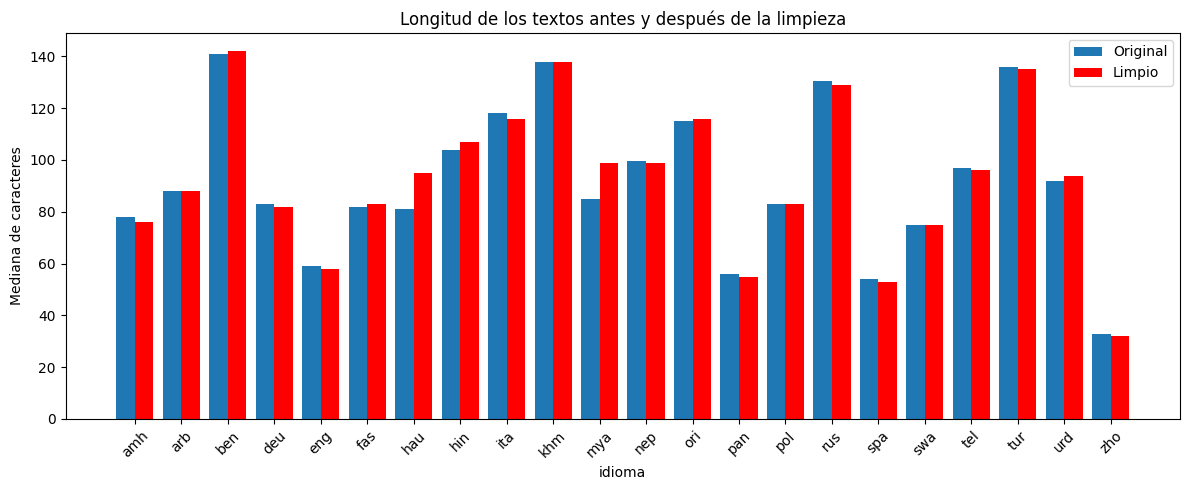

In [20]:
# Mediana de longitud antes y después de la limpieza
mediana_antes = datos.groupby('idioma')['text'].apply(lambda s: s.str.len().median())
mediana_despues = datos.groupby('idioma')['texto'].apply(lambda s: s.str.len().median())
x = np.arange(len(idiomas))

plt.figure(figsize = (12, 5))
plt.bar(x - 0.2, mediana_antes, width = 0.4, label = 'Original')
plt.bar(x + 0.2, mediana_despues, width = 0.4, color = 'red', label = 'Limpio')
plt.xticks(x, idiomas, rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Mediana de caracteres')
plt.title('Longitud de los textos antes y después de la limpieza')
plt.legend()
plt.tight_layout()
plt.show()

Después de la limpieza solo quedan letras, marcas combinantes, números, espacios, puntos y guiones bajos (de los emojis y de algunos hashtags), y ningún texto quedó vacío.

La longitud mediana casi no cambia en la mayoría de los idiomas. Las excepciones son el birmano (`mya`) y el hausa (`hau`), donde los textos crecen porque usan muchos emojis y cada uno, que ocupaba un carácter, se convierte en un nombre como `face_with_tears_of_joy`.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Representación TF-IDF</span></div>

Cada texto se representa con TF-IDF sobre n-gramas de caracteres, con los siguientes parámetros:

* `analyzer = 'char_wb'`: n-gramas de caracteres que no cruzan de una palabra a otra (cada palabra se rellena con un espacio a cada lado, así que también se marca el inicio y el final de palabra). En chino, jemer y birmano, donde no hay espacios, cada frase se trata como una sola palabra.
* `ngram_range = (2, 5)`: desde bigramas, que capturan afijos cortos, hasta pentagramas, que ya cubren raíces completas.
* `sublinear_tf = True`: usa $1 + \log(tf)$ en lugar de la frecuencia cruda, para que un n-grama repetido muchas veces en un texto no domine.
* `min_df = 2`: descarta n-gramas que aparecen en un solo texto, porque no generalizan.
* `lowercase = False`: los textos ya están en minúsculas.

El vectorizador se ajusta solo con `train` y después transforma `test`, de modo que ni el vocabulario ni los pesos IDF usan información de prueba. Se construyen dos versiones: un vectorizador **global**, con todos los idiomas, y un vectorizador **por idioma**.

In [21]:
parametros = dict(analyzer = 'char_wb', ngram_range = (2, 5), sublinear_tf = True,
                  min_df = 2, lowercase = False, dtype = np.float32)

# Ejemplo de los n-gramas que genera una palabra
print(TfidfVectorizer(**parametros).build_analyzer()('odio.'))

[' o', 'od', 'di', 'io', 'o.', '. ', ' od', 'odi', 'dio', 'io.', 'o. ', ' odi', 'odio', 'dio.', 'io. ', ' odio', 'odio.', 'dio. ']


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Vectorizador global</span></div>

In [22]:
es_train = datos['particion'] == 'train'

vectorizador_global = TfidfVectorizer(**parametros)
X_train_global = vectorizador_global.fit_transform(datos.loc[es_train, 'texto'])
X_test_global = vectorizador_global.transform(datos.loc[~es_train, 'texto'])

print(f'Dimensión de train: {X_train_global.shape}')
print(f'Dimensión de test: {X_test_global.shape}')
print(f'n-gramas distintos de cero por texto (mediana): {int(np.median(np.diff(X_train_global.indptr)))}')
print(f'Densidad de la matriz de train: {X_train_global.nnz / np.prod(X_train_global.shape):.6f}')

Dimensión de train: (73677, 763193)
Dimensión de test: (33288, 763193)
n-gramas distintos de cero por texto (mediana): 230
Densidad de la matriz de train: 0.000350


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Vectorizadores por idioma</span></div>

In [23]:
vectorizadores = {}
X_train_idioma = {}
X_test_idioma = {}

for idioma in idiomas:
    en_idioma = datos['idioma'] == idioma
    vectorizadores[idioma] = TfidfVectorizer(**parametros)
    X_train_idioma[idioma] = vectorizadores[idioma].fit_transform(datos.loc[es_train & en_idioma, 'texto'])
    X_test_idioma[idioma] = vectorizadores[idioma].transform(datos.loc[~es_train & en_idioma, 'texto'])

dimensiones = pd.DataFrame({'n_train': {i: X_train_idioma[i].shape[0] for i in idiomas},
                            'n_test': {i: X_test_idioma[i].shape[0] for i in idiomas},
                            'n_gramas': {i: X_train_idioma[i].shape[1] for i in idiomas}})
print(f"Suma de vocabularios por idioma: {dimensiones['n_gramas'].sum()}")
print(f'Vocabulario global: {X_train_global.shape[1]}')

Suma de vocabularios por idioma: 923615
Vocabulario global: 763193


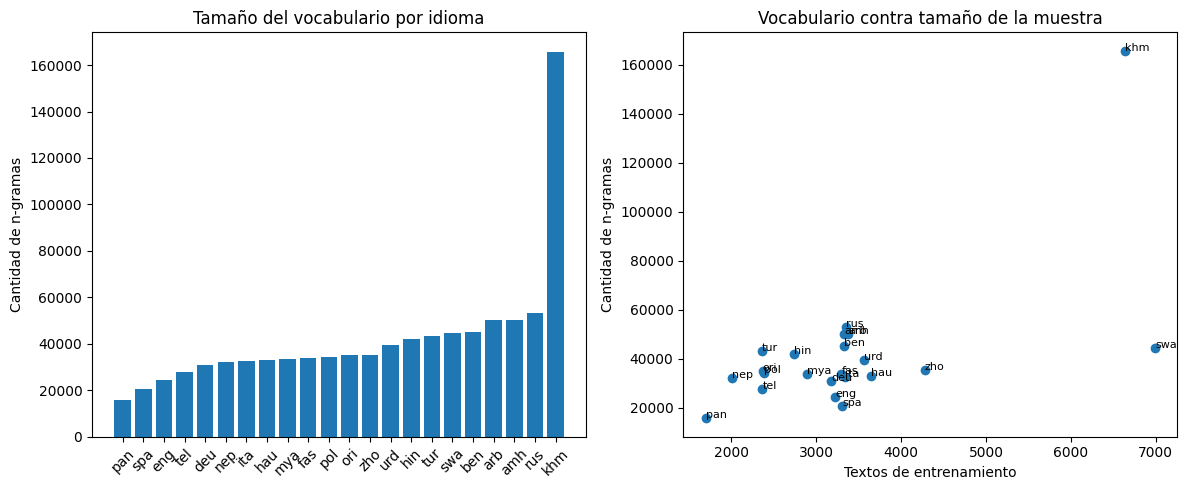

In [24]:
# Tamaño del vocabulario por idioma
orden = dimensiones.sort_values('n_gramas')

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.bar(orden.index, orden['n_gramas'])
plt.xticks(rotation = 45)
plt.ylabel('Cantidad de n-gramas')
plt.title('Tamaño del vocabulario por idioma')

plt.subplot(1, 2, 2)
plt.scatter(dimensiones['n_train'], dimensiones['n_gramas'])
for idioma in idiomas:
    plt.annotate(idioma, (dimensiones.loc[idioma, 'n_train'], dimensiones.loc[idioma, 'n_gramas']), fontsize = 8)
plt.xlabel('Textos de entrenamiento')
plt.ylabel('Cantidad de n-gramas')
plt.title('Vocabulario contra tamaño de la muestra')

plt.tight_layout()
plt.show()

El vocabulario global (≈763 mil n-gramas) es menor que la suma de los vocabularios por idioma (≈924 mil), porque los idiomas que comparten escritura (inglés, español, alemán, italiano, polaco, hausa, suajili y turco usan el alfabeto latino; árabe, persa, urdu y parte del panyabí usan el árabe) también comparten muchos n-gramas, que en el global se cuentan una sola vez.

El tamaño del vocabulario depende más de la escritura que de la cantidad de textos. El suajili tiene el doble de textos que la mayoría y un vocabulario promedio, mientras que el jemer (`khm`) tiene casi 166 mil n-gramas: al no separar palabras con espacios, `char_wb` trata frases completas como una sola palabra, y casi cada combinación de cinco caracteres es distinta. En la etapa de modelado conviene tener en cuenta que el jemer tendrá muchas más variables que textos.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">n-gramas asociados a la polarización</span></div>

Para comprobar que la representación captura información útil, se compara el peso TF-IDF promedio de cada n-grama entre textos polarizados y no polarizados. Para que sean legibles, se muestran solo n-gramas de al menos cuatro caracteres. Además, como una misma palabra genera muchos n-gramas traslapados (`' stat'`, `'stat'`, `'state'`, `'tate'`), de cada grupo se conserva solo el de mayor diferencia.

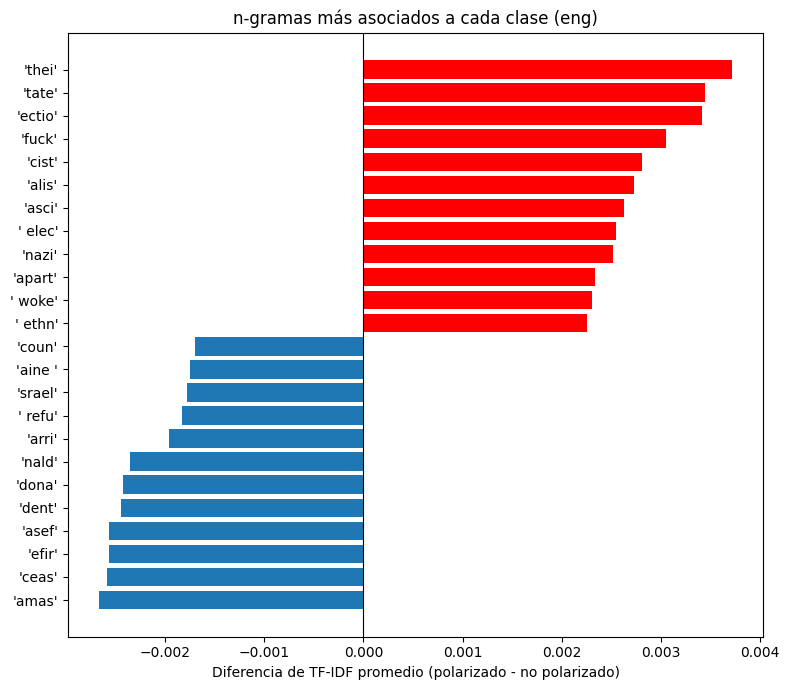

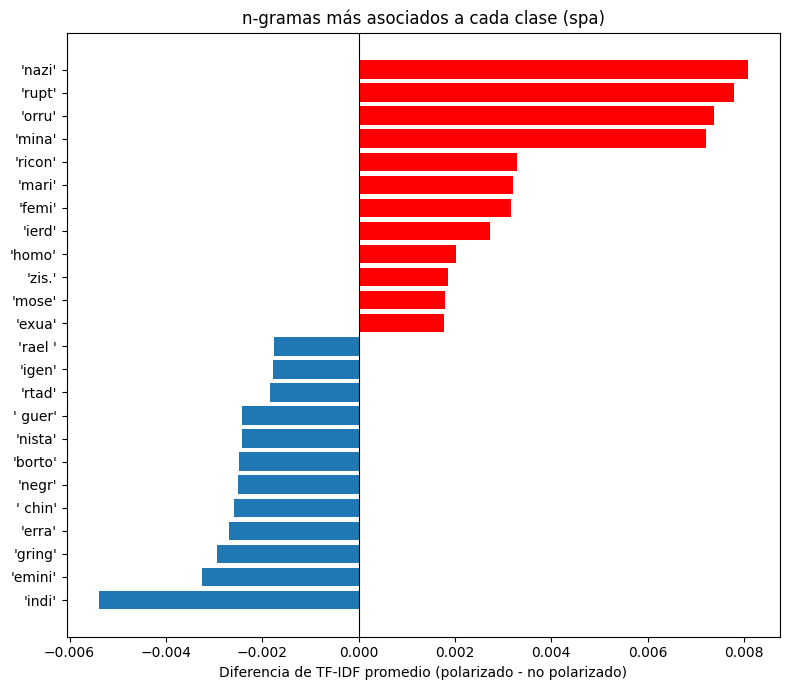

In [25]:
for idioma in ['eng', 'spa']:
    en_idioma = datos['idioma'] == idioma
    y = datos.loc[es_train & en_idioma, 'polarization'].values
    X = X_train_idioma[idioma]
    diferencia = pd.Series(np.asarray(X[y == 1].mean(axis = 0) - X[y == 0].mean(axis = 0)).ravel(),
                           index = vectorizadores[idioma].get_feature_names_out())
    diferencia = diferencia[diferencia.index.str.strip().str.len() >= 4]

    # Se descartan los n-gramas que comparten un trigrama con otro de mayor diferencia
    seleccion = {}
    for signo, candidatos in [(-1, diferencia.sort_values()), (1, diferencia.sort_values(ascending = False))]:
        elegidos = []
        for ngrama in candidatos.index:
            trigramas = {ngrama.strip()[k:k + 3] for k in range(len(ngrama.strip()) - 2)}
            if all(trigramas.isdisjoint(t) for _, t in elegidos):
                elegidos.append((ngrama, trigramas))
            if len(elegidos) == 12:
                break
        seleccion[signo] = [n for n, _ in elegidos]
    extremos = pd.concat([diferencia[seleccion[-1]], diferencia[seleccion[1]].iloc[::-1]])

    plt.figure(figsize = (8, 7))
    plt.barh([repr(n) for n in extremos.index], extremos.values,
             color = ['tab:blue' if v < 0 else 'red' for v in extremos.values])
    plt.axvline(0, color = 'black', linewidth = 0.8)
    plt.xlabel('Diferencia de TF-IDF promedio (polarizado - no polarizado)')
    plt.title(f'n-gramas más asociados a cada clase ({idioma})')
    plt.tight_layout()
    plt.show()

Los n-gramas tienen sentido:

* **Inglés:** del lado polarizado aparecen *their/they* (el *ellos* del discurso nosotros contra ellos), *racist/fascist*, *nazi*, *woke*, *apartheid* y *election*. Del lado no polarizado aparecen *hamas*, *ceasefire*, *israel*, *refugee* y *donald*, que corresponden a titulares de noticias.
* **Español:** del lado polarizado aparecen *nazi/feminazis*, *corrupto*, *maricón*, *homo* y *mierda*. Del lado no polarizado aparecen *india*, *feminismo*, *gringo*, *chino*, *aborto* y *guerra*.

Los temas sensibles (Israel, aborto, feminismo) aparecen del lado no polarizado, mientras que el lado polarizado lo marcan los insultos y las etiquetas despectivas (*feminazi* frente a *feminismo*). Esto sugiere que la polarización depende más de cómo se habla de un tema que del tema mismo, y es algo que los n-gramas sí pueden captar.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Guardado</span></div>

Se guardan dos tipos de archivos:

* `data/procesado/`: textos limpios con sus etiquetas (`train.csv`, `test.csv`), en el mismo orden que las filas de las matrices.
* `data/tfidf/`: vectorizadores ajustados (`joblib`) y matrices dispersas (`.npz`). La matriz global sigue el orden de los CSV y las de cada idioma siguen el orden de las filas de ese idioma en los CSV. Esta carpeta pesa cientos de MB y se puede regenerar con este notebook, así que está excluida del repositorio en `.gitignore`.

In [26]:
os.makedirs(ruta_procesado, exist_ok = True)
os.makedirs(os.path.join(ruta_tfidf, 'idioma'), exist_ok = True)

# Textos limpios con etiquetas
columnas = ['id', 'idioma', 'texto'] + etiquetas
datos.loc[es_train, columnas].to_csv(os.path.join(ruta_procesado, 'train.csv'), index = False)
datos.loc[~es_train, columnas].to_csv(os.path.join(ruta_procesado, 'test.csv'), index = False)

# Vectorizadores y matrices
joblib.dump(vectorizador_global, os.path.join(ruta_tfidf, 'vectorizador_global.joblib'))
sparse.save_npz(os.path.join(ruta_tfidf, 'X_train_global.npz'), X_train_global)
sparse.save_npz(os.path.join(ruta_tfidf, 'X_test_global.npz'), X_test_global)

joblib.dump(vectorizadores, os.path.join(ruta_tfidf, 'vectorizadores_idioma.joblib'))
for idioma in idiomas:
    sparse.save_npz(os.path.join(ruta_tfidf, 'idioma', f'X_train_{idioma}.npz'), X_train_idioma[idioma])
    sparse.save_npz(os.path.join(ruta_tfidf, 'idioma', f'X_test_{idioma}.npz'), X_test_idioma[idioma])

for carpeta in [ruta_procesado, ruta_tfidf]:
    tamano = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(carpeta) for f in fs)
    print(f'{carpeta}: {tamano / 1e6:.1f} MB')

data\procesado: 29.9 MB
data\tfidf: 294.4 MB


# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

* Se eliminaron de `train` los 4 textos que también estaban en `test`; en dos de ellos las etiquetas no coincidían.
* La limpieza es la misma para los 22 idiomas y se apoya en propiedades Unicode, no en reglas de cada idioma: normalización NFKC, marcadores unificados (`xxuser`, `xxurl`), caracteres repetidos reducidos a dos, emojis convertidos en tokens, hashtags sin `#`, signos de fin de oración de cualquier escritura convertidos en punto, minúsculas (con la regla especial del turco) y espacios colapsados.
* Usar `regex` con categorías Unicode en lugar de `re` fue indispensable: con `\w` se habrían destruido las palabras en hindi, bengalí, telugu, oriya, nepalí, panyabí, jemer y birmano.
* La representación TF-IDF de n-gramas de caracteres (2 a 5, `char_wb`) produce un vocabulario global de ≈763 mil n-gramas y 22 vocabularios por idioma, de entre 16 mil (`pan`) y 166 mil (`khm`) n-gramas. Ambas versiones quedaron guardadas en `data/tfidf/` para compararlas en la etapa de modelado.
* Una primera comparación entre clases muestra que los n-gramas capturan señal útil: insultos, etiquetas despectivas y pronombres de grupo se asocian a la polarización, mientras que el vocabulario de noticias se asocia a los textos no polarizados.